In [1]:
import pandas as pd
import polars as pl
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
outputs_dir = "../3_outputs/sqY2H"

df = pl.read_csv(f'{outputs_dir}/edges_df.csv', null_values=".", infer_schema_length=10000)

# dedup
df = df.with_columns(
    pl.when(pl.col("aa_change").is_null())
    .then(pl.lit("wt"))
    .otherwise(pl.col("aa_change"))
    .alias("aa_change")
)
df = df.with_columns(
    (pl.col("symbol") + "_" + 
     pl.col("ad_symbol") + "_" + 
     pl.col("aa_change")).alias("ppi_group_clean")
)

df = df.sort("db_mut_id", descending=True).unique(subset=["ppi_group_clean"], keep="first")

df
# drop WT

df = df.filter(pl.col("db_mut_id") != 0)

df = df.to_pandas()

df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,seq_ad,seq_db,db_seq_final_right,manual_correction_applied,consensus_score,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc,ppi_group_clean
0,VUSAPWT2B1r05_010,E11,VUSAPWT2B1r05_007_008_009_010_011_012,VUSAPWT2B1,r17,LWH25,2,False,1235,None,...,1,1,Y,False,537.386468,3.858183,2.0,469.198393,0.195373,LITAF_HPCAL4_Asn30Tyr
1,VUSAPWT1B1r05_015,A15,VUSAPWT1B1r05_013_014_015_016_017_018,VUSAPWT1B1,r11,LWH25,1,False,56215,None,...,1,1,Y,False,512.621483,NaN,4.0,435.661607,0.234190,LITAF_HIP1_Trp116Gly
2,VUSAPWT6B1r05_016,O15,VUSAPWT6B1r05_013_014_015_016_017_018,VUSAPWT6B1,r17,LWH25,6,False,14269,None,...,1,1,Y,True,520.724272,1.571553,3.0,496.386781,0.068919,GFAP_ZNF774_Lys279Glu
3,VUSAPWT1B2r04_026,M13,VUSAPWT1B2r04_025_026_027_028_029_030,VUSAPWT1B2,r10,LWH10,1,False,2767,None,...,1,1,Y,False,411.919144,0.795777,4.0,423.524579,-0.039989,GALE_GALE_Lys257Arg
4,VUSAPWT1B2r03_031,I07,VUSAPWT1B2r03_031_032_033_034_035_036,VUSAPWT1B2,r09,LWH1,1,False,2920,None,...,1,1,Y,False,248.143145,11.093638,2.0,267.516891,-0.108038,GFAP_GFAP_Asn77Ser
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1845,VUSAPWT1B1r04_032,O11,VUSAPWT1B1r04_031_032_033_034_035_036,VUSAPWT1B1,r10,LWH10,1,False,11922,None,...,1,1,Y,False,378.032640,0.152028,3.0,344.815113,0.132321,MLH1_MYOG_Ser106Arg
1846,VUSAPWT1B2r05_025,G03,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,11229,None,...,1,1,Y,False,91.474470,103.087478,0.0,254.189013,-1.464439,KRT6A_KIFC3_Glu163Lys
1847,VUSAPWT1B1r04_015,O07,VUSAPWT1B1r04_013_014_015_016_017_018,VUSAPWT1B1,r10,LWH10,1,False,11132,None,...,1,1,Y,False,512.220068,NaN,3.0,467.899414,0.130299,LITAF_EPN1_Leu122Val
1848,VUSAPWT1B1r05_034,K07,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,6811,None,...,1,1,Y,False,428.506990,7.575253,3.0,287.612485,0.573548,TPM1_MAD1L1_Ser215Leu


## NO WT SIGMA, ONLY ERROR

Optimizing parameters...

=== OPTIMIZED PARAMETERS ===
Mutant Mean (Fixed):          -5.0000
Mutant Intrinsic Sig: 1.8546
Measurement Error:    0.6513
Bound (Fixed):        -2.0000


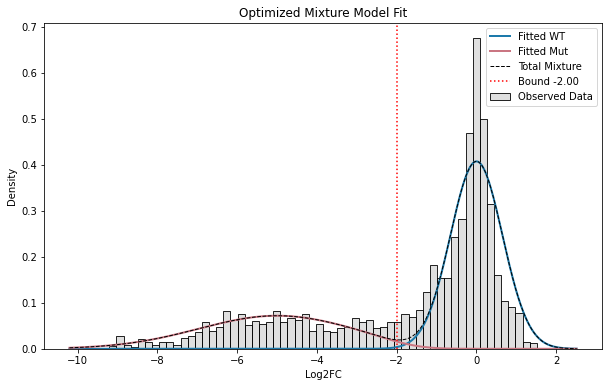


=== CUTOFFS ===
Log2FC at LLR > 3 (WT):      -1.1181
Log2FC at LLR < -3 (Mutant): -2.1357


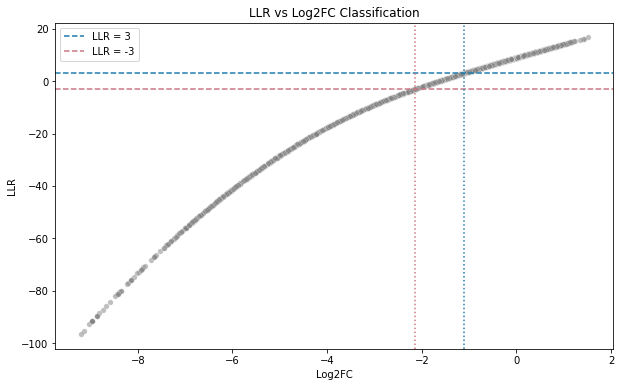

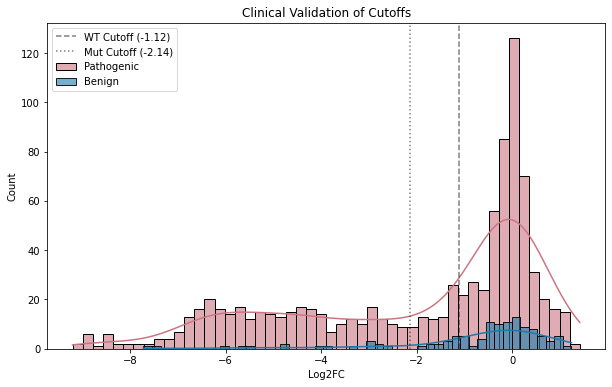

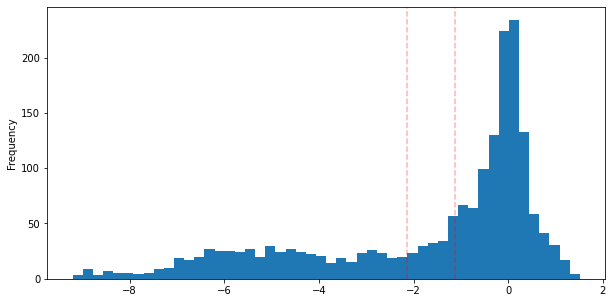

In [3]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# ==========================================
# 1. SETUP & DATA LOADING
# ==========================================
log2fc_values = df['log2fc'].dropna().to_numpy()
FIXED_BOUND = -2 # Hard biological limit
FIXED_MU_PERTURBED = -5 # Fixed mean for mutant distribution

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================
def get_convolved_pdf(x_data, mu, sigma_bio, bound, sigma_error):
    """
    Computes the PDF of a Truncated Normal (intrinsic) convolved with Normal (noise).
    """
    var_prior = sigma_bio**2
    var_measurement = sigma_error**2
    sigma_combined = np.sqrt(var_prior + var_measurement)
    
    # A. Un-truncated distribution (Prior + Noise)
    log_py = stats.norm.logpdf(x_data, loc=mu, scale=sigma_combined)
    
    # B. Posterior Parameters for the Truncation Term
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (mu / var_prior + x_data / var_measurement)
    
    # C. Truncation Adjustment Terms
    t = (bound - mu_post) / sigma_post
    log_post_cdf = stats.norm.logcdf(t)
    
    alpha = (bound - mu) / sigma_bio
    log_Z = stats.norm.logcdf(alpha)
    
    # Final Log PDF
    log_result = log_py + log_post_cdf - log_Z
    return np.exp(log_result)

def negative_log_likelihood(params):
    """
    Objective function for optimization.
    Params: [sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error]
    """
    sigma_mut, w_mut, sigma_error = params
    
    
    # --- WT COMPONENT (Standard Normal Convolution) ---
    pdf_wt = stats.norm.pdf(log2fc_values, loc=0, scale=sigma_error)
    
    # --- MUTANT COMPONENT (Truncated Convolution) ---
    pdf_mut = get_convolved_pdf(log2fc_values, FIXED_MU_PERTURBED, sigma_mut, FIXED_BOUND, sigma_error)
    
    # --- MIXTURE ---
    pdf_mix = (1 - w_mut) * pdf_wt + w_mut * pdf_mut
    pdf_mix = np.maximum(pdf_mix, 1e-100) # Safety floor
    
    return -np.sum(np.log(pdf_mix))

# ==========================================
# 3. OPTIMIZATION
# ==========================================
# Guesses: sigma_wt, w_mut, sigma_error
initial_guess = [2.0, 0.2, 0.5]

bounds = [
    (0.5, 10.0),    # sigma_mut
    (0.01, 0.99),   # w_mut
    (0.01, 0.99)    # sigma_error
]

print("Optimizing parameters...")
res = minimize(negative_log_likelihood, initial_guess, bounds=bounds, method='L-BFGS-B')

# Unpack optimized parameters
opt_sigma_mut, opt_w_mut, opt_sigma_error = res.x

print("\n=== OPTIMIZED PARAMETERS ===")
print(f"Mutant Mean (Fixed):          {FIXED_MU_PERTURBED:.4f}")
print(f"Mutant Intrinsic Sig: {opt_sigma_mut:.4f}")
print(f"Measurement Error:    {opt_sigma_error:.4f}")
print(f"Bound (Fixed):        {FIXED_BOUND:.4f}")

# ==========================================
# 4. VISUALIZATION (FIT CHECK)
# ==========================================
plt.figure(figsize=(10, 6))
sns.histplot(log2fc_values, stat='density', bins=60, color='silver', alpha=0.5, label='Observed Data')

x_plot = np.linspace(min(log2fc_values)-1, max(log2fc_values)+1, 1000)

# WT Curve
y_wt = (1 - opt_w_mut) * stats.norm.pdf(x_plot, loc=0, scale=opt_sigma_error)

# Mut Curve
y_mut_raw = get_convolved_pdf(x_plot, FIXED_MU_PERTURBED, opt_sigma_mut, FIXED_BOUND, opt_sigma_error)
y_mut = opt_w_mut * y_mut_raw

# Total
y_total = y_wt + y_mut

plt.plot(x_plot, y_wt, color='#1D7AAB', lw=2, label='Fitted WT')
plt.plot(x_plot, y_mut, color='#CA7682', lw=2, label='Fitted Mut')
plt.plot(x_plot, y_total, color='black', linestyle='--', lw=1, label='Total Mixture')
plt.axvline(FIXED_BOUND, color='red', linestyle=':', label=f'Bound {FIXED_BOUND:.2f}')

plt.title("Optimized Mixture Model Fit")
plt.xlabel("Log2FC")
plt.ylabel("Density")
plt.legend()
plt.show()

# ==========================================
# 5. LLR CALCULATION
# ==========================================
def compute_perturbation_llr(df_in, mu_mut, sigma_mut, bound, sigma_error):
    """
    Calculates LLR using the consistent optimized parameters.
    """
    # Work on a copy (Pandas)
    df_out = df_in.copy()
    if isinstance(df_out, pl.DataFrame):
        df_out = df_out.to_pandas()
        
    log2fc = df_out["log2fc"].to_numpy()
    
    # Handle row-specific error if available, otherwise use optimized global error
    if "error_log2fc" in df_out.columns:
        row_error = df_out["error_log2fc"].fillna(sigma_error).to_numpy()
    else:
        row_error = np.full_like(log2fc, sigma_error)
        
    row_error = np.maximum(row_error, 1e-3) # Safety floor

    # --- Null Hypothesis (WT) ---
    # Model: Normal(0, scale = sqrt(Error^2 + Intrinsic_WT^2))
    # scale_wt = np.sqrt(row_error**2 + sigma_wt**2)
    loglik_wt = stats.norm.logpdf(log2fc, loc=0, scale=row_error)
    
    # --- Alt Hypothesis (Mutant) ---
    # Model: Convolved Truncated Normal
    pdt_mut = get_convolved_pdf(log2fc, mu_mut, sigma_mut, bound, row_error)
    loglik_mut = np.log(np.maximum(pdt_mut, 1e-100))  # Safety floor
    
    # --- Final Score ---
    # LLR = Log(P(WT)) - Log(P(Mut))
    # Positive = WT, Negative = Mutant
    df_out["perturbation_LLR"] = loglik_wt - loglik_mut
    
    return pl.from_pandas(df_out)

# Run Calculation
df_result_pl = compute_perturbation_llr(
    df, 
    mu_mut=FIXED_MU_PERTURBED, 
    sigma_mut=opt_sigma_mut,
    bound=FIXED_BOUND, 
    sigma_error=opt_sigma_error
)
df_result = df_result_pl.to_pandas()

# ==========================================
# 6. THRESHOLDS & VALIDATION PLOTS
# ==========================================
df_sorted = df_result.sort_values('perturbation_LLR')
x_vals = df_sorted['log2fc'].values
y_vals = df_sorted['perturbation_LLR'].values

# Interpolate Cutoffs
cutoff_wt = np.interp(3, y_vals, x_vals)
cutoff_mut = np.interp(-3, y_vals, x_vals)

print(f"\n=== CUTOFFS ===")
print(f"Log2FC at LLR > 3 (WT):      {cutoff_wt:.4f}")
print(f"Log2FC at LLR < -3 (Mutant): {cutoff_mut:.4f}")

# Plot 1: LLR Curve
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_result, x='log2fc', y='perturbation_LLR', alpha=0.5, color='grey', s=30)
plt.axhline(3, color='#1D7AAB', ls='--', label='LLR = 3')
plt.axhline(-3, color='#CA7682', ls='--', label='LLR = -3')
plt.axvline(cutoff_wt, color='#1D7AAB', ls=':')
plt.axvline(cutoff_mut, color='#CA7682', ls=':')
plt.title("LLR vs Log2FC Classification")
plt.xlabel("Log2FC")
plt.ylabel("LLR")
plt.legend()
plt.show()

# Plot 2: Pathogenic vs Benign Validation
pathogenic_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
).to_pandas()

benign_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"])
).to_pandas()

plt.figure(figsize=(10, 6))
sns.histplot(pathogenic_df["log2fc"], bins=50, kde=True, color="#CA7682", label="Pathogenic", alpha=0.6)
sns.histplot(benign_df["log2fc"], bins=50, kde=True, color="#1D7AAB", label="Benign", alpha=0.6)

plt.axvline(x=cutoff_wt, color='black', linestyle='--', alpha=0.5, label=f'WT Cutoff ({cutoff_wt:.2f})')
plt.axvline(x=cutoff_mut, color='black', linestyle=':', alpha=0.5, label=f'Mut Cutoff ({cutoff_mut:.2f})')

plt.title("Clinical Validation of Cutoffs")
plt.xlabel("Log2FC")
plt.legend()
plt.show()

# Plot combined histogram
df.log2fc.plot.hist(bins=50, figsize=(10,5))
plt.axvline(x=cutoff_wt, color='red', linestyle='--', alpha=0.3)
plt.axvline(x=cutoff_mut, color='red', linestyle='--', alpha=0.3)
plt.show()

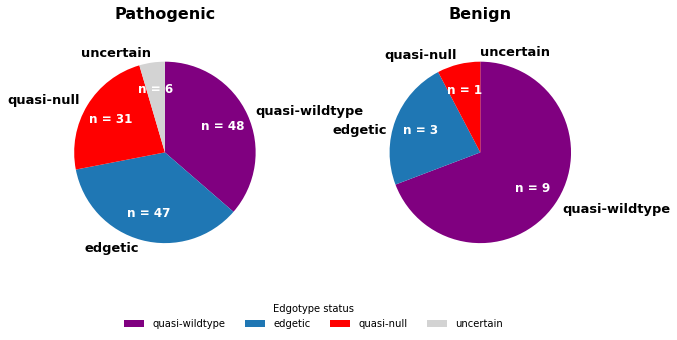

In [4]:
## Edgetic

df = df_result_pl.with_columns(
    pl.when(pl.col('perturbation_LLR').is_null())
    .then(pl.lit(None))
    .when(pl.col('perturbation_LLR') <= -3)
    .then(pl.lit('perturbed'))
    .when(pl.col('perturbation_LLR') >= 3)
    .then(pl.lit('unperturbed'))
    .otherwise(pl.lit('uncertain'))
    .alias('perturbation_status')
)

df = df.to_pandas()

def edgotype_status(status_list):
    status_list = status_list.to_list()
    if len(status_list) == 1:
        return np.nan
    if pd.isnull(status_list).all():
        return np.nan
    if 'perturbed' in status_list and 'unperturbed' in status_list:
        return 'edgetic'
    elif status_list.count('perturbed') >= 2:
        return 'quasi-null'
    elif status_list.count('unperturbed') >= 2:
        return 'quasi-wildtype'
    else:
        return 'uncertain'

# N PPIs, N successful, N_perturbed, N_unperturbed, N-uncertain
edgotype = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(edgotype_status)
)

edgotype = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(edgotype_status)
)
edgotype = edgotype.to_frame().rename(columns={"perturbation_status": "edgotype_status"})
edgotype['n_ppi'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["ad_symbol"]
    .nunique())
edgotype['n_measured_ppi'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["log2fc"]
    .apply(lambda x: x.notnull().sum()))

for status in ['perturbed', 'unperturbed', 'uncertain']:
    edgotype[f'n_{status}'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(lambda x: (x == status).sum()))
# TODO
edgotype = edgotype.reset_index()

n_b4 = edgotype.shape[0]
edgotype = pd.merge(edgotype, 
         df.loc[:, ['symbol', 
                    'gene_variant',
                    'clinvar_clnsig_clean',
                    ]].drop_duplicates(),
            on=["gene_variant"],
            how='left')


order = ['quasi-wildtype', 'edgetic', 'quasi-null', 'uncertain']

# from matplotlib.patches import Patch

# fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(6,12), gridspec_kw={'wspace': 0.4})

# for cat, ax in zip(['Pathogenic', 'Benign'], axs):
#     vc = (edgotype.loc[(edgotype['clinvar_clnsig_clean'] == cat)
#                  & (edgotype['n_measured_ppi'] >= 2), 
#                  'edgotype_status']
#                  .value_counts(dropna=True)
#                  .reindex(order)
#                  .fillna(0))
#     wedges, texts, autotexts = ax.pie(
#         vc,
#         labels=vc.index,
#         autopct=lambda x: f"n = {x / 100 * vc.sum():.0f}" if x > 0 else '',
#         startangle=90,
#         counterclock=False,
#         colors=['purple', 'C0', 'red', 'lightgrey'],
#         labeldistance=1.1,
#         textprops={'color': 'black', 'weight': 'bold'},
#         pctdistance=0.7,
#     )
#     ax.set_title(cat)
#     # Move "edgetic" label lower on the right pie
#     if cat == "Benign":
#         for t in texts:
#             if t.get_text() == "edgetic":
#                 x, y = t.get_position()
#                 t.set_position((x, y - 0.15))  # Move label lower
                
# # Custom legend
# legend_elements = [
#     Patch(facecolor='purple', label='quasi-wildtype'),
#     Patch(facecolor='C0', label='edgetic'),
#     Patch(facecolor='red', label='quasi-null'),
#     Patch(facecolor='lightgrey', label='uncertain'),
# ]

# # Adjust bbox_to_anchor to be within view (e.g., 0.1 or 0.2) 
# # or use loc='lower center' without a strict bbox to test visibility
# fig.legend(
#     handles=legend_elements,
#     title="Edgotype status",
#     loc="upper center",
#     bbox_to_anchor=(0.5, 0.15), 
#     ncol=2
# )

# plt.show()

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 1. Adjusted figsize to be wider than tall for side-by-side pies
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))

# 2. Reserve space at the bottom (bottom=0.2 means 20% of figure height)
fig.subplots_adjust(bottom=0.25, wspace=0.3)

for cat, ax in zip(['Pathogenic', 'Benign'], axs):
    vc = (edgotype.loc[(edgotype['clinvar_clnsig_clean'] == cat)
                 & (edgotype['n_measured_ppi'] >= 2), 
                 'edgotype_status']
                 .value_counts(dropna=True)
                 .reindex(order)
                 .fillna(0))
    
    wedges, texts, autotexts = ax.pie(
        vc,
        labels=vc.index,
        autopct=lambda x: f"n = {x / 100 * vc.sum():.0f}" if x > 0 else '',
        startangle=90,
        counterclock=False,
        colors=['purple', 'C0', 'red', 'lightgrey'],
        labeldistance=1.1,
        textprops={'color': 'black', 'weight': 'bold', 'fontsize': 13},
        pctdistance=0.7,
    )
    ax.set_title(cat, fontsize=16, weight='bold', pad=20)

    for autotext in autotexts:
        autotext.set_fontsize(12)
        autotext.set_weight('bold')
        autotext.set_color('white')
    
    # Move "edgetic" label lower on the right pie
    
    if cat == "Benign":
        for t in texts:
            if t.get_text() == "edgetic":
                x, y = t.get_position()
                t.set_position((x, y - 0.15))

legend_elements = [
    Patch(facecolor='purple', label='quasi-wildtype'),
    Patch(facecolor='C0', label='edgetic'),
    Patch(facecolor='red', label='quasi-null'),
    Patch(facecolor='lightgrey', label='uncertain'),
]

# 3. Use loc="lower center" and move it slightly up from 0
fig.legend(
    handles=legend_elements,
    title="Edgotype status",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.05),
    ncol=4,          # Set to 4 to keep it on one line if space allows
    frameon=False    # Cleaner look for papers
)

plt.show()

In [6]:
edgotype

,gene_variant,edgotype_status,n_ppi,n_measured_ppi,n_perturbed,n_unperturbed,n_uncertain,symbol,clinvar_clnsig_clean
0,ACSF3_Arg10Trp,NaN,1,1,1,0,0,ACSF3,VUS
1,ACSF3_Arg471Trp,quasi-wildtype,3,3,0,3,0,ACSF3,Conflicting
2,ACSF3_Arg558Trp,quasi-null,3,3,3,0,0,ACSF3,Pathogenic
3,ACSF3_Asp457Asn,quasi-null,3,3,3,0,0,ACSF3,VUS
4,ACSF3_Glu359Lys,quasi-null,3,3,3,0,0,ACSF3,Pathogenic
...,...,...,...,...,...,...,...,...,...
499,VHL_Tyr112His,NaN,1,1,1,0,0,VHL,Pathogenic
500,VHL_Tyr134Cys,NaN,1,1,0,1,0,VHL,Pathogenic
501,VHL_Val125Ala,NaN,1,1,0,1,0,VHL,Pathogenic
502,ZMYND10_Leu266Pro,quasi-null,2,2,2,0,0,ZMYND10,Pathogenic


In [16]:
orf_distances = pd.read_csv(f'{outputs_dir}/orf_distances.csv')
orf_distances

,db_orf_id,db_mut_id,num_edges,clinvar_clnsig_clean,euclid_dist_legacy,euclid_dist_interactor,euclid_dist_wt_imp,nan_euclid_dist_rms,mean_signed_difference,mean_log2fc,...,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant
0,3689,214861,2,Pathogenic,0.746257,0.746257,0.746257,0.746257,0.497027,5.033744,...,0.000000,>90,<10,125851,autosomal dominant,OMIM,Rare genetic developmental defect during embry...,3,"MATURITY-ONSET DIABETES OF THE YOUNG, TYPE 2",False
1,13320,204006,1,Pathogenic,0.216665,0.216665,0.216665,0.216665,-0.216665,-0.720341,...,40.217392,>90,10-90,263400;263400;193300,multiple,OMIM,Rare genetic eye disease; Rare genetic renal d...,8,"ERYTHROCYTOSIS, FAMILIAL, 2; ERYTHROCYTOSIS, F...",False
2,2651,214302,1,Conflicting,0.226063,0.226063,0.226063,0.226063,0.226063,2.549225,...,0.000000,>90,<10,601780,autosomal recessive,OMIM,Rare genetic eye disease; Rare genetic neurolo...,3,"CEROID LIPOFUSCINOSIS, NEURONAL, 6A",False
3,3438,201181,2,Benign,0.510604,0.355550,0.355456,0.502691,0.355456,6.033919,...,16.935484,>90,10-90,604400;619832;604400;614302,autosomal dominant,OMIM,Rare genetic cardiac disease; Laminopathy; Rar...,3,"ARRHYTHMOGENIC RIGHT VENTRICULAR DYSPLASIA, FA...",False
4,11805,20082,2,Others,0.305357,0.305357,0.305357,0.305357,-0.143991,-0.451969,...,NaN,NaN,NaN,NaN,NaN,NaN,Rare genetic vascular disease; Rare genetic sy...,2,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499,100016069,2644,1,Conflicting,0.459287,0.459287,0.459287,0.459287,0.459287,1.586233,...,21.808512,>90,10-90,170390;609622,autosomal dominant,OMIM,Rare genetic cardiac disease; Rare genetic neu...,2,ANDERSEN CARDIODYSRHYTHMIC PERIODIC PARALYSIS;...,False
500,55855,219422,3,Others,0.427960,0.427960,0.427960,0.427960,0.120106,0.575502,...,47.938145,>90,10-90,NaN,NaN,NaN,Rare genetic skin disease,1,NaN,False
501,4723,8952,2,Pathogenic,0.471626,0.471626,0.471626,0.471626,-0.289888,-0.710011,...,51.533740,>90,10-90,115196;611878,autosomal dominant,OMIM,Rare genetic cardiac disease; Laminopathy; Rar...,3,"CARDIOMYOPATHY, FAMILIAL HYPERTROPHIC, 3; CARD...",False
502,13796,218149,2,Others,0.401637,0.401637,0.401637,0.401637,0.177963,0.538167,...,53.374230,>90,10-90,NaN,NaN,NaN,Rare genetic hematologic disease,1,NaN,False


In [17]:
# merge edgotype status on orf_distances
orf_distances = orf_distances.merge(edgotype[['gene_variant', 'edgotype_status']], on='gene_variant', how='left')
orf_distances#.to_csv('./tmp/orf_dist_edgotpye.csv', index=False)

,db_orf_id,db_mut_id,num_edges,clinvar_clnsig_clean,euclid_dist_legacy,euclid_dist_interactor,euclid_dist_wt_imp,nan_euclid_dist_rms,mean_signed_difference,mean_log2fc,...,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,edgotype_status
0,3689,214861,2,Pathogenic,0.746257,0.746257,0.746257,0.746257,0.497027,5.033744,...,>90,<10,125851,autosomal dominant,OMIM,Rare genetic developmental defect during embry...,3,"MATURITY-ONSET DIABETES OF THE YOUNG, TYPE 2",False,edgetic
1,13320,204006,1,Pathogenic,0.216665,0.216665,0.216665,0.216665,-0.216665,-0.720341,...,>90,10-90,263400;263400;193300,multiple,OMIM,Rare genetic eye disease; Rare genetic renal d...,8,"ERYTHROCYTOSIS, FAMILIAL, 2; ERYTHROCYTOSIS, F...",False,NaN
2,2651,214302,1,Conflicting,0.226063,0.226063,0.226063,0.226063,0.226063,2.549225,...,>90,<10,601780,autosomal recessive,OMIM,Rare genetic eye disease; Rare genetic neurolo...,3,"CEROID LIPOFUSCINOSIS, NEURONAL, 6A",False,NaN
3,3438,201181,2,Benign,0.510604,0.355550,0.355456,0.502691,0.355456,6.033919,...,>90,10-90,604400;619832;604400;614302,autosomal dominant,OMIM,Rare genetic cardiac disease; Laminopathy; Rar...,3,"ARRHYTHMOGENIC RIGHT VENTRICULAR DYSPLASIA, FA...",False,NaN
4,11805,20082,2,Others,0.305357,0.305357,0.305357,0.305357,-0.143991,-0.451969,...,NaN,NaN,NaN,NaN,NaN,Rare genetic vascular disease; Rare genetic sy...,2,NaN,False,quasi-wildtype
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499,100016069,2644,1,Conflicting,0.459287,0.459287,0.459287,0.459287,0.459287,1.586233,...,>90,10-90,170390;609622,autosomal dominant,OMIM,Rare genetic cardiac disease; Rare genetic neu...,2,ANDERSEN CARDIODYSRHYTHMIC PERIODIC PARALYSIS;...,False,NaN
500,55855,219422,3,Others,0.427960,0.427960,0.427960,0.427960,0.120106,0.575502,...,>90,10-90,NaN,NaN,NaN,Rare genetic skin disease,1,NaN,False,quasi-wildtype
501,4723,8952,2,Pathogenic,0.471626,0.471626,0.471626,0.471626,-0.289888,-0.710011,...,>90,10-90,115196;611878,autosomal dominant,OMIM,Rare genetic cardiac disease; Laminopathy; Rar...,3,"CARDIOMYOPATHY, FAMILIAL HYPERTROPHIC, 3; CARD...",False,quasi-wildtype
502,13796,218149,2,Others,0.401637,0.401637,0.401637,0.401637,0.177963,0.538167,...,>90,10-90,NaN,NaN,NaN,Rare genetic hematologic disease,1,NaN,False,uncertain


In [19]:
orf_distances.GeneSymbol.isna().sum()

5